In [1]:
import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
PARENT_PATH = os.path.dirname(os.getcwd())
sys.path.append(PARENT_PATH)
from config import Config

In [3]:
df = pd.read_csv(Config.RAW_GAMES_DATA_FILE)
df.head()

,CpuName,CpuNumberOfCores,CpuNumberOfThreads,CpuBaseClock,CpuCacheL1,CpuCacheL2,CpuCacheL3,CpuDieSize,CpuFrequency,CpuMultiplier,...,GpuShaderModel,GpuNumberOfShadingUnits,GpuNumberOfTMUs,GpuTextureRate,GpuNumberOfTransistors,GpuVulkan,GameName,GameResolution,GameSetting,FPS
0,b'Intel Core i9-9900K',8.0,16.0,100.0,512.0,2048.0,16.0,NaN,3600.0,36.0,...,b'6.5',4352.0,272.0,420200.0,18600.0,b'1.2.131',b'callOfDutyWW2',1080.0,b'med',225.3
1,b'Intel Core i7-9700K',8.0,8.0,100.0,512.0,2048.0,12.0,NaN,3600.0,36.0,...,b'6.5',4352.0,272.0,420200.0,18600.0,b'1.2.131',b'callOfDutyWW2',1080.0,b'med',223.3
2,b'Intel Core i7-8700K',6.0,12.0,100.0,384.0,1536.0,12.0,NaN,3700.0,37.0,...,b'6.5',4352.0,272.0,420200.0,18600.0,b'1.2.131',b'callOfDutyWW2',1080.0,b'med',207.3
3,b'Intel Core i7-7700K',4.0,8.0,100.0,256.0,1024.0,8.0,NaN,4200.0,42.0,...,b'6.5',4352.0,272.0,420200.0,18600.0,b'1.2.131',b'callOfDutyWW2',1080.0,b'med',201.3
4,b'Intel Core i5-9400F',6.0,6.0,100.0,384.0,1536.0,9.0,NaN,2900.0,29.0,...,b'6.5',4352.0,272.0,420200.0,18600.0,b'1.2.131',b'callOfDutyWW2',1080.0,b'med',199.2


In [4]:
df.shape

(24624, 44)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24624 entries, 0 to 24623
Data columns (total 44 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CpuName                    24624 non-null  str    
 1   CpuNumberOfCores           24624 non-null  float64
 2   CpuNumberOfThreads         24624 non-null  float64
 3   CpuBaseClock               24624 non-null  float64
 4   CpuCacheL1                 24624 non-null  float64
 5   CpuCacheL2                 24624 non-null  float64
 6   CpuCacheL3                 24624 non-null  float64
 7   CpuDieSize                 11664 non-null  float64
 8   CpuFrequency               24624 non-null  float64
 9   CpuMultiplier              24624 non-null  float64
 10  CpuMultiplierUnlocked      24624 non-null  str    
 11  CpuProcessSize             24624 non-null  float64
 12  CpuTDP                     24624 non-null  float64
 13  CpuNumberOfTransistors     11664 non-null  float64
 14  C

In [6]:
df.describe()

,CpuNumberOfCores,CpuNumberOfThreads,CpuBaseClock,CpuCacheL1,CpuCacheL2,CpuCacheL3,CpuDieSize,CpuFrequency,CpuMultiplier,CpuProcessSize,...,GpuMemorySize,GpuPixelRate,GpuProcessSize,GpuNumberOfROPs,GpuNumberOfShadingUnits,GpuNumberOfTMUs,GpuTextureRate,GpuNumberOfTransistors,GameResolution,FPS
count,24624.000000,24624.000000,24624.0,24624.000000,24624.000000,24624.000000,11664.000000,24624.000000,24624.000000,24624.000000,...,24624.000000,24624.000000,24624.000000,24624.000000,24624.00000,24624.000000,24624.000000,24624.000000,24624.0,24624.000000
mean,6.315789,10.842105,100.0,515.368421,2506.105263,18.210526,0.000126,3589.473684,35.894737,11.947368,...,7333.333333,89045.925926,15.259259,57.777778,2237.62963,139.851852,215336.296296,8377.777778,1080.0,123.959369
std,2.078823,5.203982,0.0,233.521609,1398.698066,14.229906,0.000059,317.719889,3.177199,3.017095,...,2775.611026,28211.657786,5.783828,19.023439,866.31581,54.144738,83501.932511,3533.754477,0.0,54.610080
min,2.000000,4.000000,100.0,128.000000,512.000000,3.000000,0.000074,2800.000000,28.000000,7.000000,...,3000.000000,36430.000000,7.000000,24.000000,768.00000,48.000000,66820.000000,3300.000000,1080.0,22.200000
25%,6.000000,6.000000,100.0,384.000000,1536.000000,9.000000,0.000074,3400.000000,34.000000,7.000000,...,6000.000000,68360.000000,12.000000,48.000000,1536.00000,96.000000,157100.000000,5700.000000,1080.0,83.600000
50%,6.000000,12.000000,100.0,512.000000,2048.000000,16.000000,0.000074,3600.000000,36.000000,14.000000,...,8000.000000,86400.000000,14.000000,64.000000,2304.00000,144.000000,202000.000000,7200.000000,1080.0,114.300000
75%,8.000000,16.000000,100.0,576.000000,3072.000000,32.000000,0.000192,3800.000000,38.000000,14.000000,...,8000.000000,109400.000000,16.000000,64.000000,2560.00000,160.000000,277300.000000,10800.000000,1080.0,154.100000
max,12.000000,24.000000,100.0,1152.000000,6144.000000,64.000000,0.000192,4200.000000,42.000000,14.000000,...,16000.000000,139200.000000,28.000000,96.000000,4352.00000,272.000000,420200.000000,18600.000000,1080.0,396.400000


In [7]:
df.isna().sum() / len(df) * 100

CpuName                        0.000000
CpuNumberOfCores               0.000000
CpuNumberOfThreads             0.000000
CpuBaseClock                   0.000000
CpuCacheL1                     0.000000
CpuCacheL2                     0.000000
CpuCacheL3                     0.000000
CpuDieSize                    52.631579
CpuFrequency                   0.000000
CpuMultiplier                  0.000000
CpuMultiplierUnlocked          0.000000
CpuProcessSize                 0.000000
CpuTDP                         0.000000
CpuNumberOfTransistors        52.631579
CpuTurboClock                  0.000000
GpuName                        0.000000
GpuArchitecture                0.000000
GpuBandwidth                   0.000000
GpuBaseClock                   0.000000
GpuBoostClock                  0.000000
GpuBus.interface               0.000000
GpuNumberOfComputeUnits       77.777778
GpuDieSize                     0.000000
GpuDirectX                     0.000000
GpuNumberOfExecutionUnits    100.000000


In [8]:
df.dropna(inplace=True, axis=1)

In [9]:
for col in df.columns:
    if df[col].nunique() < 2:
        df.drop(columns=[col], inplace=True)

In [10]:
for col in df.select_dtypes(include='object').columns:
    if df[col][0].startswith("b'"):
        df[col] = df[col].str.strip("b'").str.strip("'")

C:\Users\clt\AppData\Local\Temp\ipykernel_29628\2037462359.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [11]:
df['CpuMultiplierUnlocked'] = df['CpuMultiplierUnlocked'].astype('Int64')
df['GpuShaderModel'] = df['GpuShaderModel'].astype('float64')
df['GpuOpenCL'] = df['GpuOpenCL'].astype('float64')

In [12]:
df['GpuMemorySize'].head()

0    11000.0
1    11000.0
2    11000.0
3    11000.0
4    11000.0
Name: GpuMemorySize, dtype: float64

In [13]:
df['GpuMemorySize'] = df['GpuMemorySize'] / 1000

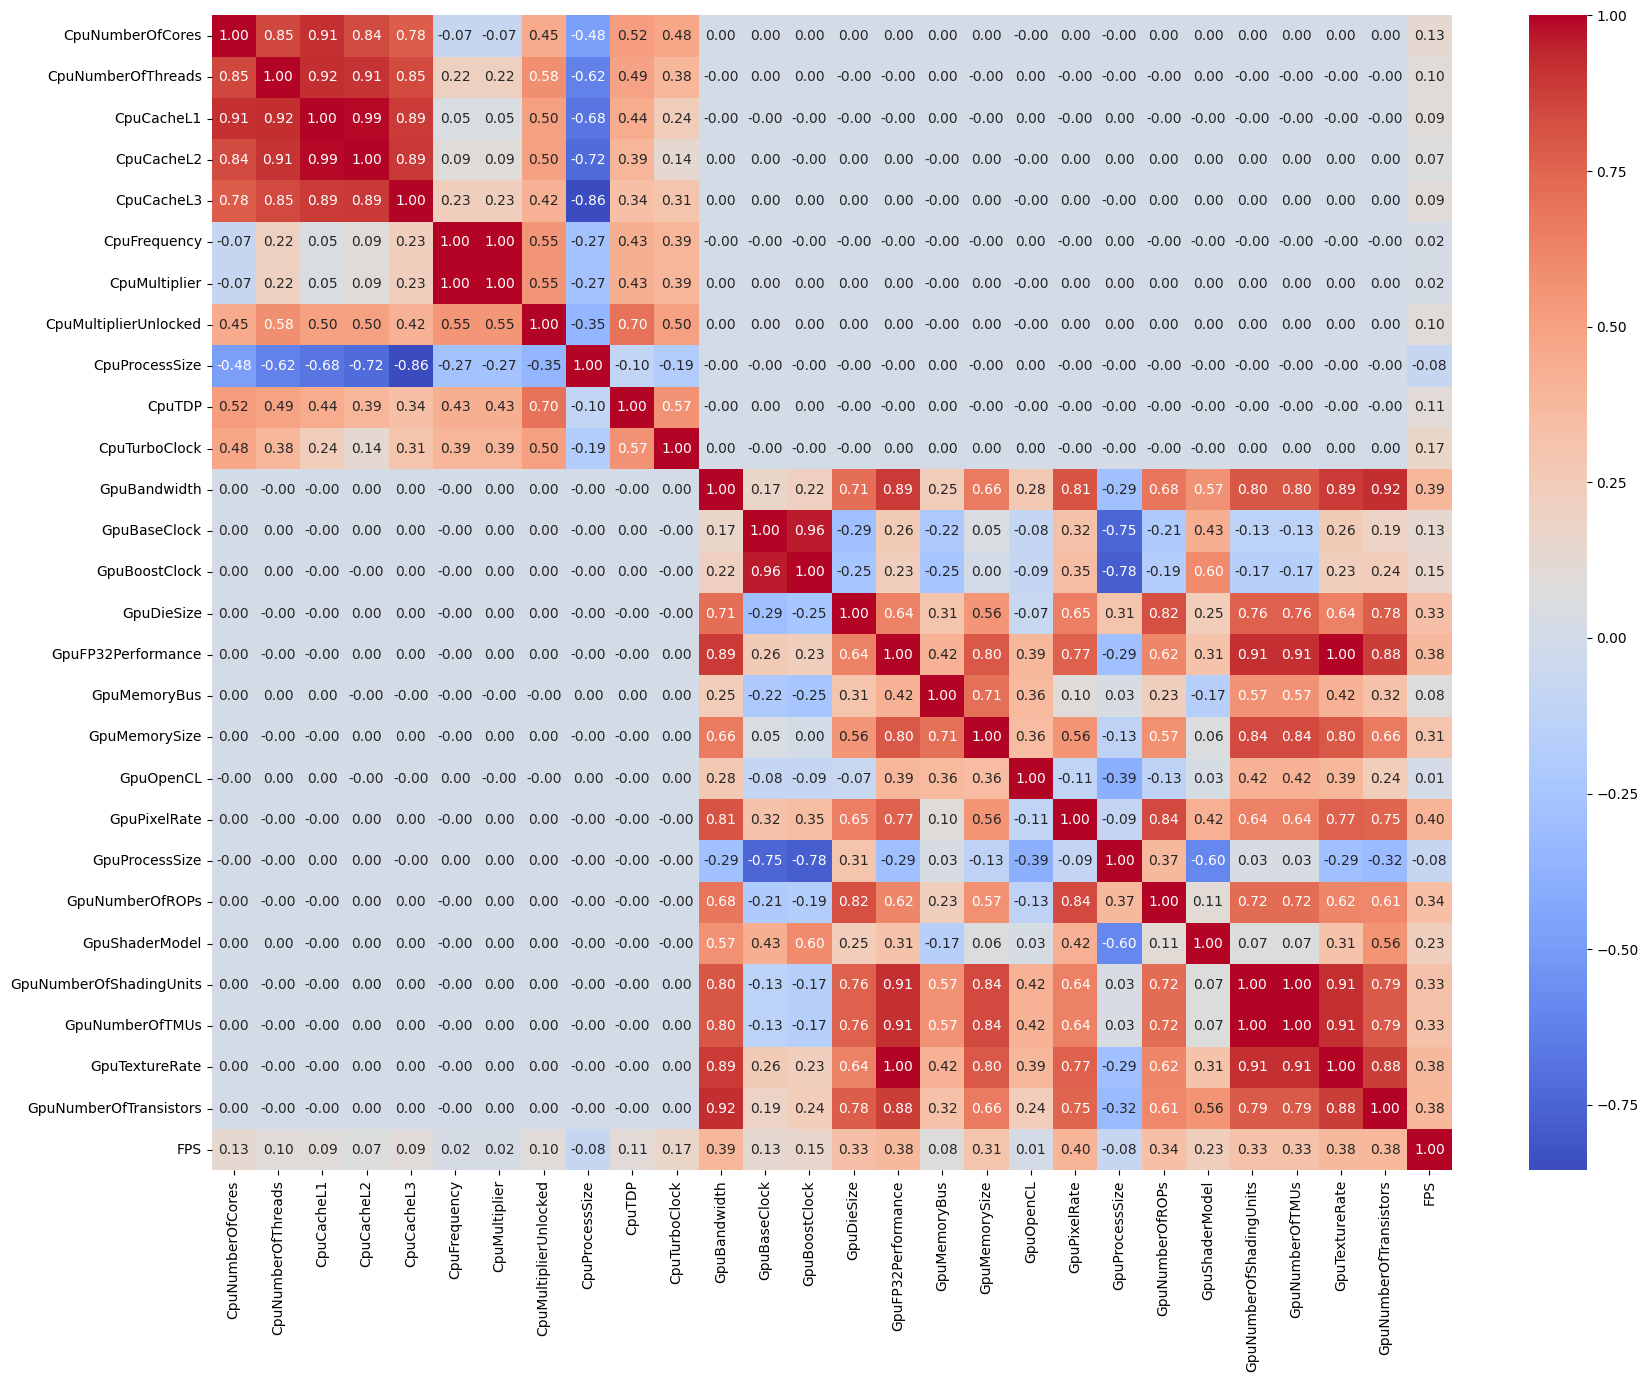

In [14]:
plt.figure(figsize=(20, 15))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [15]:
columns_to_drop = ['GpuNumberOfTMUs', 'CpuFrequency', 'CpuMultiplier', 'GpuBaseClock',
                   'GpuFP32Performance', 'CpuCacheL1', 'CpuCacheL2', 'CpuCacheL3', 'GpuProcessSize',
                   'GpuMemoryBus', 'CpuProcessSize', 'GpuBandwidth', 'GpuNumberOfShadingUnits', 'GpuOpenCL']
df.drop(columns=columns_to_drop, inplace=True)

In [16]:
df.columns

Index(['CpuName', 'CpuNumberOfCores', 'CpuNumberOfThreads',
       'CpuMultiplierUnlocked', 'CpuTDP', 'CpuTurboClock', 'GpuName',
       'GpuArchitecture', 'GpuBoostClock', 'GpuBus.interface', 'GpuDieSize',
       'GpuDirectX', 'GpuMemorySize', 'GpuMemoryType', 'GpuPixelRate',
       'GpuNumberOfROPs', 'GpuShaderModel', 'GpuTextureRate',
       'GpuNumberOfTransistors', 'GpuVulkan', 'GameName', 'GameSetting',
       'FPS'],
      dtype='str')

In [17]:
names = ["CpuName", "GpuName", "GameName"]
for col in df.select_dtypes(include='object').columns:
    if col not in names:
        print(col, df[col].unique())

GpuArchitecture <StringArray>
['Turing', 'Pascal', 'Maxwell 2.0', 'RDNA 1.0', 'GCN 5.0', 'GCN 4.0']
Length: 6, dtype: str
GpuBus.interface <StringArray>
['PCIe 3.0 x16', 'PCIe 4.0 x16']
Length: 2, dtype: str
GpuDirectX <StringArray>
['12 Ultimate', '12']
Length: 2, dtype: str
GpuMemoryType <StringArray>
['GDDR6', 'GDDR5X', 'GDDR5', 'HBM2']
Length: 4, dtype: str
GpuVulkan <StringArray>
['1.2.131', '1.1.126', '1.1.125']
Length: 3, dtype: str
GameSetting <StringArray>
['med', 'max']
Length: 2, dtype: str


C:\Users\clt\AppData\Local\Temp\ipykernel_29628\3113705903.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [18]:
df.shape

(24624, 23)

In [19]:
df.head()

,CpuName,CpuNumberOfCores,CpuNumberOfThreads,CpuMultiplierUnlocked,CpuTDP,CpuTurboClock,GpuName,GpuArchitecture,GpuBoostClock,GpuBus.interface,...,GpuMemoryType,GpuPixelRate,GpuNumberOfROPs,GpuShaderModel,GpuTextureRate,GpuNumberOfTransistors,GpuVulkan,GameName,GameSetting,FPS
0,Intel Core i9-9900K,8.0,16.0,1,95.0,5000.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,225.3
1,Intel Core i7-9700K,8.0,8.0,1,95.0,4900.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,223.3
2,Intel Core i7-8700K,6.0,12.0,1,95.0,4700.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,207.3
3,Intel Core i7-7700K,4.0,8.0,1,91.0,4500.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,201.3
4,Intel Core i5-9400F,6.0,6.0,0,65.0,4100.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,199.2


In [20]:
df.to_csv(Config.PROCCESSED_GAMES_DATA_FILE, index=False)